# 07 · Business impact and statistical testing

**Guidelines covered:** Model development (statistical models) · Business insight

This notebook turns the text analysis into business evidence. Every claim is backed by a statistical test; a summary of all tests is in [`reports/statistical_tests/`](../reports/statistical_tests/).

| Cell | Business question | Method | Main result |
|---|---|---|---|
| M1 | Which problems does each review mention? | Keyword rules built from the BERTopic themes, applied to **all** reviews | 15.3% of reviews mention at least one problem |
| **M2** | **How many stars does a review lose when it mentions a problem?** | **OLS regression with HC3 robust errors, controlling for app and review length** | **Blocking problems cost the most: AutoPay −1.22, crashes −1.10, security blocks −1.10 stars; slowness −0.52. R² = 0.38** |
| M3 | What should each app fix first, and what is it worth? | Per-app regression + "what if we fixed it" simulation | BHIM registration/OTP/SIM: −0.99 stars per mention, +0.18 stars potential gain |
| V1 | Did Paytm version 10.84.5 hurt ratings? | Mann-Whitney U and chi-square tests | 1-star share 9.2% → 17.6% → 6.7%; p < 0.001 |
| V2 | Which releases were significantly worse? | Mann-Whitney U per version, Bonferroni-corrected (38 versions) | 5 versions flagged |
| R1 | How well do companies answer complaints? | Reply rate, median reply time, template share | BHIM 98% answered but after 46 h, 96% templates; Google Pay 44% |
| C1 | Is the crash result robust? | Same regression with a stricter keyword list | −1.10 → −0.91 stars, still significant |

**Why cell M2 matters.** Counting complaints shows what is *common*; M2 shows what *hurts*. Because it uses all 85,150 reviews (happy and unhappy) and keyword mentions that can appear in any review, it is not circular, and controlling for app and review length compares like with like. The coefficients are associations, not proof of cause.

**Inputs:** `reviews_with_sentiment.parquet`, `complaints_with_themes.parquet` · **Outputs:** `rating_drivers_all_apps.csv`, `priority_matrix.csv`, `release_monitor.csv`, `reply_analysis.csv`, `theme_mentions.parquet`, figures 09–10

**How to run:** open in Google Colab, keep the project folder at `MyDrive/upi-complaint-analytics` (or change `BASE` in the first code cell) and run the cells from top to bottom. The outputs shown are from the original run.

## Phase 8a: rating drivers and fix priorities

In [ ]:
# ===== Phase 8a – Business impact: rating drivers, priority matrix, "what if we fixed it" =====
# Cell M1: tag EVERY review with the themes it mentions (keyword rules built from the BERTopic theme words).
# Why not reuse the BERTopic themes directly? They exist only for complaints, which are low-rated by
# definition, so regressing the rating on them would be circular. Mentions work for happy and unhappy reviews.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf, warnings
warnings.filterwarnings('ignore', message='This pattern is interpreted as a regular expression')
pd.set_option('display.width', 220)

BASE = '/content/drive/MyDrive/upi-complaint-analytics'
PROC = f'{BASE}/data/processed'
rev = pd.read_parquet(f'{PROC}/reviews_with_sentiment.parquet')
themes_cmp = pd.read_parquet(f'{PROC}/complaints_with_themes.parquet')[['review_id', 'theme']]

THEME_RULES = {
    'otp':      ('Registration, OTP & SIM verification', r"\botps?\b|auto ?read|auto ?fetch|\bsms\b|verif|onboard|regist|\bsim\b|mobile data"),
    'security': ('Security / device-integrity blocks', r"security (alert|check|reason|issue|warning)|device environment|\benvironment\b|\broot(ed)?\b|malicious|suspicious app|developer option|usb debugging|accessibility|integrity|download(ed)? (it )?from (the )?(google )?play|(installed|install|update[d]?) from (the )?play ?store|verifying (the |your )?device|too many (login )?attempts"),
    'login':    ('Login & account blocked', r"\blog ?in\b|account (is |was |got |has been )?(blocked|suspended|locked|frozen|closed)|\bsuspend"),
    'crash':    ('App not opening / crashes / updates', r"not open|not working|not work\b|crash|clos(e|es|ed|ing) (automatically|itself|suddenly)|getting closed|gets closed|stops? working|stopped working|not responding|\bhang|freez|glitch|disappear|after (the |this |latest )?update|new update|not updat"),
    'slow':     ('Slow performance', r"\bslow|\blag|takes? (too )?(much|long) time|too much time|loading"),
    'payment':  ('Failed / pending payments', r"fail|pending|deduct|debited|not (received|credited|reflect)|(money|payment|amount|transaction) (is |was |got )?(stuck|cut)|refund|(not able|unable) to (pay|send|transfer|recharge)|(payment|transaction|transfer)s? (issue|problem|error|not)|insufficient|wrong balance|not paid"),
    'support':  ('Customer support', r"customer (care|support|service)|helpline|toll ?free|no response|no reply|support team|\bchat\b|executive|\bcalls?\b|complain|ticket|e-?mail|\bmail\b|contact|help ?desk"),
    'cashback': ('Cashback & rewards', r"cash ?back|reward|scratch ?card|coupon|voucher|\boffers?\b"),
    'fees':     ('Fees & charges', r"platform fee|convenience fee|extra charge|\bcharges?\b|\bfees?\b|surcharge|\bgst\b"),
    'upilite':  ('UPI Lite & UPI PIN', r"upi lite|\blite\b|upi pin|\bpin\b"),
    'autopay':  ('AutoPay / mandates', r"auto ?pay|mandate|subscription"),
    'qr':       ('QR scanning & location', r"\bscan|\bqr\b|camera|location"),
    'receipt':  ('Payment receipt / screenshot', r"screenshot|screen shot|receipt|transaction id|\bproof\b"),
    'ads':      ('Ads, notifications & add-ons', r"\bads?\b|advertis|notification|promotion|\bspam|\bgold\b|\bloans?\b|insurance"),
}
for code, (name, pat) in THEME_RULES.items():
    rev['m_' + code] = rev.text_light.str.contains(pat, regex=True).astype(int)
MCOLS = ['m_' + c for c in THEME_RULES]
NAME = {'m_' + c: v[0] for c, v in THEME_RULES.items()}
print('Reviews mentioning at least one theme:', round(rev[MCOLS].max(1).mean() * 100, 1), '%')

# Validation: share of the complaints BERTopic placed in a theme that the theme's keywords also catch
chk = themes_cmp.merge(rev[['review_id'] + MCOLS], on='review_id')
val = pd.DataFrame({NAME[c]: {'bertopic_complaints': int((chk.theme == NAME[c]).sum()),
                              'keyword_coverage_%': round(chk.loc[chk.theme == NAME[c], c].mean() * 100, 1),
                              'mention_rate_all_reviews_%': round(rev[c].mean() * 100, 2)} for c in MCOLS}).T
print(val.sort_values('bertopic_complaints', ascending=False).to_string())

Reviews mentioning at least one theme: 15.3 %
                                      bertopic_complaints  keyword_coverage_%  mention_rate_all_reviews_%
Registration, OTP & SIM verification               1761.0                84.8                        2.67
Failed / pending payments                          1353.0                32.8                        1.92
App not opening / crashes / updates                1274.0                53.6                        3.99
Security / device-integrity blocks                  868.0                27.0                        0.60
Cashback & rewards                                  784.0                87.5                        2.52
Customer support                                    494.0                51.8                        1.91
Slow performance                                    477.0                76.5                        1.86
Login & account blocked                             384.0                56.2                        1.39


### Cell M2: the rating-driver model (key statistical result)
How many stars does a review lose when it mentions each problem? Ordinary least squares on all 85,150 reviews, with robust (HC3) standard errors, controlling for the app and the review length.

Reviews: 85150 | R-squared: 0.382 | log_words effect: -0.525
                               theme  stars_effect  ci_low  ci_high  p_value  mention_rate_%
                  AutoPay / mandates        -1.220  -1.402   -1.037   0.0000            0.31
 App not opening / crashes / updates        -1.101  -1.160   -1.042   0.0000            3.99
  Security / device-integrity blocks        -1.098  -1.235   -0.961   0.0000            0.60
                      Fees & charges        -0.860  -1.025   -0.695   0.0000            0.52
Registration, OTP & SIM verification        -0.844  -0.917   -0.770   0.0000            2.67
           Failed / pending payments        -0.760  -0.842   -0.677   0.0000            1.92
             Login & account blocked        -0.738  -0.835   -0.641   0.0000            1.39
                    Customer support        -0.712  -0.795   -0.629   0.0000            1.91
        Ads, notifications & add-ons        -0.681  -0.794   -0.568   0.0000            1.07
         

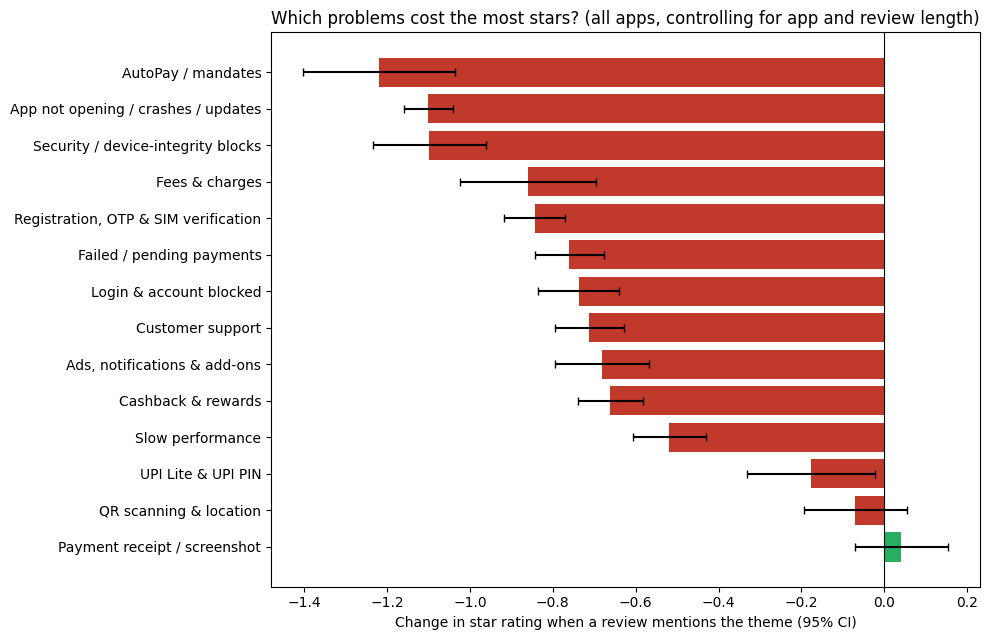

In [ ]:
# Cell M2: rating driver model (all apps): how many stars is a review worth less when it mentions a theme?
# OLS with robust (HC3) standard errors, controlling for the app and for review length.
rev['log_words'] = np.log1p(rev.n_words)
ols = smf.ols('rating ~ ' + ' + '.join(MCOLS) + ' + log_words + C(app)', data=rev).fit(cov_type='HC3')
ci = ols.conf_int()
coef = pd.DataFrame({'theme': [NAME[c] for c in MCOLS],
                     'stars_effect': ols.params[MCOLS].values.round(3),
                     'ci_low': ci.loc[MCOLS, 0].values.round(3),
                     'ci_high': ci.loc[MCOLS, 1].values.round(3),
                     'p_value': ols.pvalues[MCOLS].values.round(4),
                     'mention_rate_%': (rev[MCOLS].mean().values * 100).round(2)}).sort_values('stars_effect')
print('Reviews:', int(ols.nobs), '| R-squared:', round(ols.rsquared, 3),
      '| log_words effect:', round(ols.params['log_words'], 3))
print(coef.to_string(index=False))
coef.to_csv(f'{BASE}/reports/rating_drivers_all_apps.csv', index=False)

c2 = coef.sort_values('stars_effect', ascending=False)
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(c2.theme, c2.stars_effect, xerr=[c2.stars_effect - c2.ci_low, c2.ci_high - c2.stars_effect],
        color=['#C0392B' if v < 0 else '#27AE60' for v in c2.stars_effect], capsize=3)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Change in star rating when a review mentions the theme (95% CI)')
ax.set_title('Which problems cost the most stars? (all apps, controlling for app and review length)')
plt.tight_layout(); plt.savefig(f'{BASE}/reports/figures/09_rating_drivers.png', dpi=150); plt.show()

### Cell M3: priority matrix and "what if we fixed it" per app


=== BHIM: current average 2.675 stars | top fixes by potential rating gain ===
                               theme  reviews_mentioning  prevalence_%  stars_effect  p_value  gain_if_fixed  gain_if_halved
Registration, OTP & SIM verification                1929         19.45        -0.986   0.0000          0.182           0.091
 App not opening / crashes / updates                1532         15.45        -0.549   0.0000          0.079           0.039
                    Slow performance                1128         11.38        -0.420   0.0000          0.044           0.022
             Login & account blocked                 793          8.00        -0.509   0.0000          0.038           0.019
           Failed / pending payments                 617          6.22        -0.597   0.0000          0.034           0.017
                  Cashback & rewards                 718          7.24        -0.257   0.0002          0.014           0.007

=== Google Pay: current average 3.989 stars 

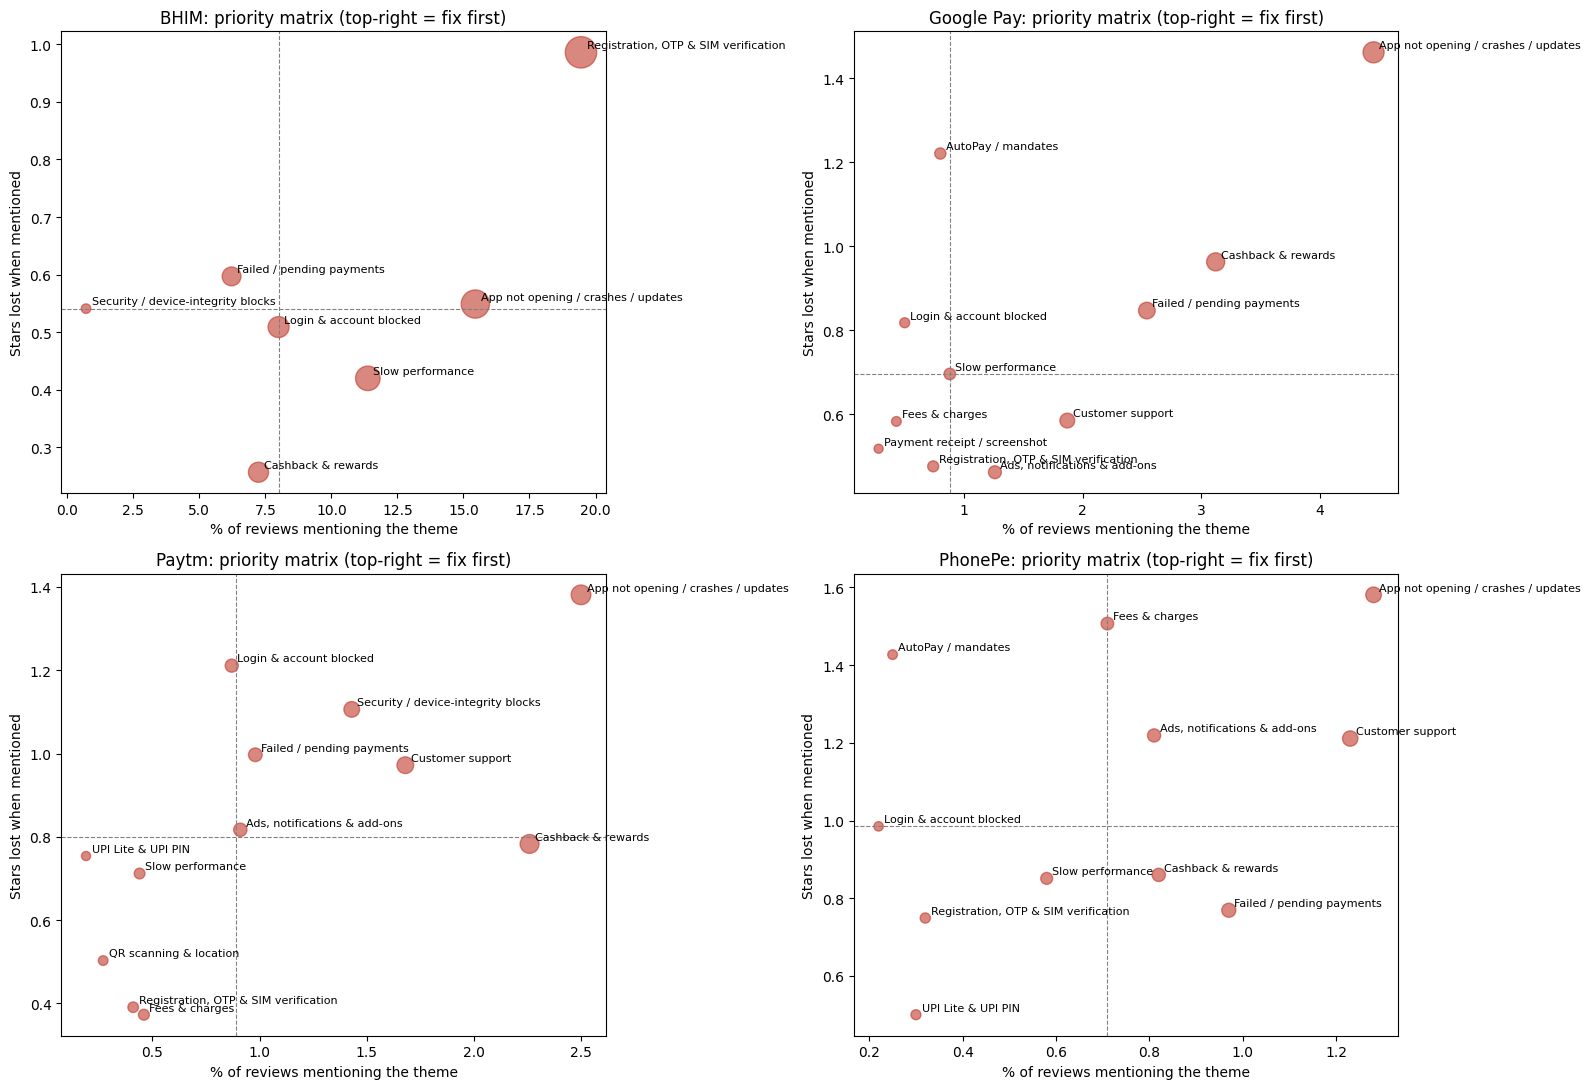

Saved priority_matrix.csv, rating_drivers_all_apps.csv, theme_mentions.parquet and 2 figures


In [ ]:
# Cell M3: per-app priority matrix and "what if we fixed it" simulation
# Per app: frequency (% of reviews mentioning a theme) x severity (stars lost, from a per-app regression).
# Simulation: reviews mentioning a significant theme get its star penalty back (capped at 5 stars).
apps = ['BHIM', 'Google Pay', 'Paytm', 'PhonePe']
rows = []
for a in apps:
    d = rev[rev.app == a]
    m = smf.ols('rating ~ ' + ' + '.join(MCOLS) + ' + log_words', data=d).fit(cov_type='HC3')
    base = d.rating.mean()
    for c in MCOLS:
        eff, p, n = m.params[c], m.pvalues[c], int(d[c].sum())
        penalty = -eff if (eff < 0 and p < 0.05) else 0.0
        fixed = np.where(d[c] == 1, np.minimum(5, d.rating + penalty), d.rating).mean()
        rows.append({'app': a, 'theme': NAME[c], 'reviews_mentioning': n, 'prevalence_%': round(n / len(d) * 100, 2),
                     'stars_effect': round(eff, 3), 'p_value': round(p, 4), 'current_avg': round(base, 3),
                     'gain_if_fixed': round(fixed - base, 3), 'gain_if_halved': round((fixed - base) / 2, 3)})
pri = pd.DataFrame(rows)
pri.to_csv(f'{BASE}/reports/priority_matrix.csv', index=False)
for a in apps:
    t = pri[(pri.app == a) & (pri.reviews_mentioning >= 30)].sort_values('gain_if_fixed', ascending=False)
    print(f'\n=== {a}: current average {t.current_avg.iloc[0]} stars | top fixes by potential rating gain ===')
    print(t[['theme', 'reviews_mentioning', 'prevalence_%', 'stars_effect', 'p_value', 'gain_if_fixed', 'gain_if_halved']]
          .head(6).to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, a in zip(axes.ravel(), apps):
    t = pri[(pri.app == a) & (pri.reviews_mentioning >= 30) & (pri.stars_effect < 0) & (pri.p_value < 0.05)].copy()
    t['penalty'] = -t.stars_effect
    ax.scatter(t['prevalence_%'], t.penalty, s=t.reviews_mentioning.clip(upper=3000) / 4 + 30, alpha=0.6, color='#C0392B')
    for _, r in t.iterrows():
        ax.annotate(r.theme, (r['prevalence_%'], r.penalty), fontsize=8, xytext=(4, 3), textcoords='offset points')
    if len(t):
        ax.axvline(t['prevalence_%'].median(), ls='--', c='grey', lw=0.8)
        ax.axhline(t.penalty.median(), ls='--', c='grey', lw=0.8)
    ax.set_title(f'{a}: priority matrix (top-right = fix first)')
    ax.set_xlabel('% of reviews mentioning the theme'); ax.set_ylabel('Stars lost when mentioned')
plt.tight_layout(); plt.savefig(f'{BASE}/reports/figures/10_priority_matrix.png', dpi=150); plt.show()
rev[['review_id'] + MCOLS].to_parquet(f'{PROC}/theme_mentions.parquet', index=False)
print('Saved priority_matrix.csv, rating_drivers_all_apps.csv, theme_mentions.parquet and 2 figures')

## Phase 8b: release events, release monitor and company replies

In [ ]:
# ===== Phase 8b – Version event study, release monitor, customer replies =====
# Cell V1: did Paytm version 10.84.5 really change ratings and security-block complaints? (statistical tests)
from scipy import stats
apps = ['BHIM', 'Google Pay', 'Paytm', 'PhonePe']
TARGET = '10.84.5'
p = rev[(rev.app == 'Paytm') & rev.app_version.notna()].copy()
first_seen = p.groupby('app_version').review_date.min()
p['group'] = np.where(p.app_version == TARGET, TARGET,
                      np.where(p.app_version.map(first_seen) < first_seen[TARGET], 'earlier versions', 'later versions'))
summ = p.groupby('group').agg(reviews=('review_id', 'size'), avg_rating=('rating', 'mean'),
                              pct_1_star=('rating', lambda s: (s == 1).mean() * 100),
                              pct_security_mention=('m_security', lambda s: s.mean() * 100),
                              pct_crash_mention=('m_crash', lambda s: s.mean() * 100),
                              pct_login_mention=('m_login', lambda s: s.mean() * 100)).round(2)
print(summ.loc[['earlier versions', TARGET, 'later versions']].to_string())

def compare(a, b):
    A, B = p[p.group == a], p[p.group == b]
    mw = stats.mannwhitneyu(A.rating, B.rating).pvalue
    sec = stats.chi2_contingency([[A.m_security.sum(), len(A) - A.m_security.sum()],
                                  [B.m_security.sum(), len(B) - B.m_security.sum()]])[1]
    one = stats.chi2_contingency([[(A.rating == 1).sum(), (A.rating != 1).sum()],
                                  [(B.rating == 1).sum(), (B.rating != 1).sum()]])[1]
    print(f'{a:>16} vs {b:<16} | ratings (Mann-Whitney) p = {mw:.1e} | security mentions (chi-square) p = {sec:.1e} | 1-star share p = {one:.1e}')
print()
compare('earlier versions', TARGET)
compare(TARGET, 'later versions')

# Same test on the BERTopic themes of Paytm's long complaints
pc = p.merge(themes_cmp, on='review_id')
pc['is_security'] = pc.theme == 'Security / device-integrity blocks'
print('\nSecurity-block share of Paytm complaints:', pc.groupby('group').is_security.mean().mul(100).round(1).to_dict())
A, B = pc[pc.group == TARGET], pc[pc.group != TARGET]
print('10.84.5 vs all other versions (chi-square) p =',
      f"{stats.chi2_contingency([[A.is_security.sum(), len(A) - A.is_security.sum()], [B.is_security.sum(), len(B) - B.is_security.sum()]])[1]:.1e}")

                  reviews  avg_rating  pct_1_star  pct_security_mention  pct_crash_mention  pct_login_mention
group                                                                                                        
earlier versions    14264        4.50        9.22                  1.49               1.89               0.61
10.84.5              2486        4.11       17.58                  2.90               9.41               1.21
later versions       6983        4.63        6.69                  0.47               1.06               1.03

earlier versions vs 10.84.5          | ratings (Mann-Whitney) p = 9.5e-43 | security mentions (chi-square) p = 7.8e-07 | 1-star share p = 4.9e-36
         10.84.5 vs later versions   | ratings (Mann-Whitney) p = 6.4e-72 | security mentions (chi-square) p = 1.1e-22 | 1-star share p = 2.0e-56

Security-block share of Paytm complaints: {'10.84.5': 35.0, 'earlier versions': 21.3, 'later versions': 17.7}
10.84.5 vs all other versions (chi-square) p =

In [ ]:
# Cell V2: release monitor – which versions (300+ reviews) were rated significantly worse than the rest of the same app?
# Mann-Whitney test per version, Bonferroni-corrected because many versions are tested at once.
rows = []
for a in apps:
    d = rev[(rev.app == a) & rev.app_version.notna()]
    vc = d.app_version.value_counts()
    for v in vc[vc >= 300].index:
        A, B = d[d.app_version == v], d[d.app_version != v]
        rising = (A[MCOLS].mean() - B[MCOLS].mean()).sort_values(ascending=False)
        rows.append({'app': a, 'version': v, 'first_seen': A.review_date.min().date(), 'reviews': len(A),
                     'avg_rating': round(A.rating.mean(), 2), 'rest_of_app': round(B.rating.mean(), 2),
                     'diff': round(A.rating.mean() - B.rating.mean(), 2),
                     'p_value': stats.mannwhitneyu(A.rating, B.rating).pvalue,
                     'mentions_rising_most': ', '.join(f'{NAME[c]} +{rising[c] * 100:.1f}pp' for c in rising.index[:2] if rising[c] > 0)})
mon = pd.DataFrame(rows)
mon['significant'] = mon.p_value < 0.05 / len(mon)
mon.to_csv(f'{BASE}/reports/release_monitor.csv', index=False)
pd.set_option('display.max_colwidth', 90)
print(len(mon), 'versions tested | Bonferroni threshold p <', round(0.05 / len(mon), 5))
print(mon.sort_values('diff').head(8).assign(p_value=lambda x: x.p_value.map(lambda v: f'{v:.1e}')).to_string(index=False))

38 versions tested | Bonferroni threshold p < 0.00132
       app                             version first_seen  reviews  avg_rating  rest_of_app  diff p_value                                                                  mentions_rising_most  significant
     Paytm                             10.84.5 2026-09-02     2486        4.11         4.54 -0.43 1.4e-59 App not opening / crashes / updates +7.8pp, Security / device-integrity blocks +1.7pp         True
Google Pay 331.1.2 (arm64-v8a_release_flutter) 2026-05-18     1097        3.60         4.02 -0.42 6.2e-15                  App not opening / crashes / updates +14.6pp, Slow performance +1.3pp         True
Google Pay 351.1.1 (arm64-v8a_release_flutter) 2026-09-29      444        3.73         4.00 -0.27 8.6e-04                                    Customer support +1.7pp, UPI Lite & UPI PIN +1.6pp         True
      BHIM                              4.0.24 2026-06-22     1707        2.52         2.78 -0.26 3.2e-08          Registratio

### Cell R1: company replies to complaints

In [ ]:
# Cell R1: customer replies – do unhappy users get a real answer, and how fast?
# A reply text sent 20+ times is counted as a template.
r = rev.copy()
r['replied'] = r.company_reply.notna()
r['reply_hours'] = (pd.to_datetime(r.reply_date) - pd.to_datetime(r.review_date)).dt.total_seconds() / 3600
r['template'] = r.company_reply.map(r.company_reply.value_counts()).fillna(0) >= 20
neg, pos = r[r.rating <= 2], r[r.rating == 5]
replies = pd.DataFrame({
    'reply_rate_all_%': r.groupby('app').replied.mean() * 100,
    'reply_rate_1_2_star_%': neg.groupby('app').replied.mean() * 100,
    'reply_rate_5_star_%': pos.groupby('app').replied.mean() * 100,
    'median_hours_1_2_star': neg[neg.replied].groupby('app').reply_hours.median(),
    'template_share_1_2_star_%': neg[neg.replied].groupby('app').template.mean() * 100,
    'template_share_5_star_%': pos[pos.replied].groupby('app').template.mean() * 100}).round(1)
replies.to_csv(f'{BASE}/reports/reply_analysis.csv')
print(replies.to_string())

# Which complaint themes do other users agree with most? (total and median helpful votes, not the skewed mean)
hv = themes_cmp.merge(rev[['review_id', 'app', 'helpful_votes']], on='review_id')
hv = hv[hv.theme != 'General dissatisfaction'].groupby(['app', 'theme']).helpful_votes.agg(
    complaints='size', total_votes='sum', median_votes='median')
for a in apps:
    print(f'\n{a}: themes with most helpful votes')
    print(hv.loc[a].sort_values('total_votes', ascending=False).head(4).to_string())

            reply_rate_all_%  reply_rate_1_2_star_%  reply_rate_5_star_%  median_hours_1_2_star  template_share_1_2_star_%  template_share_5_star_%
app                                                                                                                                                
BHIM                    96.8                   98.4                 93.8                   45.7                       95.9                     96.1
Google Pay              11.4                   44.1                  0.3                    0.3                        6.5                      2.5
Paytm                   96.2                   94.8                 96.5                    0.4                        8.5                     86.9
PhonePe                 25.8                   74.6                 16.9                    1.5                        0.0                     98.5

BHIM: themes with most helpful votes
                                      complaints  total_votes  median_vote

### Cell C1: robustness check

In [ ]:
# Cell C1: robustness check – does the "crashes" result survive without the vague phrase "not working"?
strict = r"not open|crash|clos(e|es|ed|ing) (automatically|itself|suddenly)|getting closed|gets closed|stopped working|not responding|\bhang|freez|glitch|disappear|after (the |this |latest )?update|new update|not updat"
rev['m_crash_strict'] = rev.text_light.str.contains(strict, regex=True).astype(int)
cols2 = [c for c in MCOLS if c != 'm_crash'] + ['m_crash_strict']
o2 = smf.ols('rating ~ ' + ' + '.join(cols2) + ' + log_words + C(app)', data=rev).fit(cov_type='HC3')
print('All apps | broad definition : effect', round(ols.params['m_crash'], 3), '| mentioned in', round(rev.m_crash.mean() * 100, 2), '% of reviews')
print('All apps | strict definition: effect', round(o2.params['m_crash_strict'], 3), '| mentioned in', round(rev.m_crash_strict.mean() * 100, 2), '% of reviews')
for a in apps:
    d = rev[rev.app == a]
    m = smf.ols('rating ~ ' + ' + '.join(cols2) + ' + log_words', data=d).fit(cov_type='HC3')
    eff, pv = m.params['m_crash_strict'], m.pvalues['m_crash_strict']
    pen = -eff if (eff < 0 and pv < 0.05) else 0
    gain = np.where(d.m_crash_strict == 1, np.minimum(5, d.rating + pen), d.rating).mean() - d.rating.mean()
    old = pri[(pri.app == a) & (pri.theme == 'App not opening / crashes / updates')].gain_if_fixed.iloc[0]
    print(f'{a:<11} strict: effect {eff:.3f} | mentioned {d.m_crash_strict.mean() * 100:.2f}% | gain if fixed {gain:.3f} (broad: {old:.3f})')

All apps | broad definition : effect -1.101 | mentioned in 3.99 % of reviews
All apps | strict definition: effect -0.909 | mentioned in 1.86 % of reviews
BHIM        strict: effect -0.384 | mentioned 6.95% | gain if fixed 0.024 (broad: 0.079)
Google Pay  strict: effect -1.248 | mentioned 2.00% | gain if fixed 0.022 (broad: 0.057)
Paytm       strict: effect -1.112 | mentioned 1.27% | gain if fixed 0.012 (broad: 0.028)
PhonePe     strict: effect -1.614 | mentioned 0.61% | gain if fixed 0.009 (broad: 0.017)
